# Ejercicio 3 — Transformada de Fourier, filtros y predicción de series temporales

**Fase 3 – Filtrado de series temporales y transformaciones en el dominio de la frecuencia**

## Objetivo
Explorar el análisis de señales en el **dominio de la frecuencia** con la Transformada Rápida de
Fourier (FFT) y aplicar distintos **filtros** (ventana de Tukey, Butterworth pasa-bajas, pasa-altas
y pasa-banda) para limpiar señales y finalmente hacer una **predicción** con Fourier sobre datos
reales de CO₂ (Mauna Loa, 1965-1980).

## Idea central de la Transformada de Fourier
Cualquier señal en el tiempo puede descomponerse como **suma de senos y cosenos** de distintas
frecuencias, amplitudes y fases. La FFT nos dice *qué frecuencias* contiene una señal y con *qué
intensidad*:

- Una **senoidal pura** → dos picos en ±su frecuencia.
- Una **constante** → un pico en 0 Hz (componente de continua).
- Una **tendencia** → componentes de **baja frecuencia** (cerca de 0).
- **Ruido blanco** → energía **en todas las frecuencias**.

## 1. Configuración y función de visualización

Primero definimos una función que dibuja cualquier señal en **ambos dominios**: tiempo (izquierda)
y frecuencia (derecha). La frecuencia se calcula con `np.fft.fftfreq` y se reordena con
`np.fft.fftshift` para que el eje quede de negativo a positivo.

In [1]:
#importamos librerías y definimos la función de visualización
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal

# Vector de tiempo: 5 segundos muestreados con 512 puntos
time = np.linspace(0, 5, 512)

def grafica_tiempo_frecuencia(t, y, titulo='', xlim_frec=(-20, 20)):
    '''Dibuja la señal y en el dominio del tiempo y en el dominio de la frecuencia.'''
    frec = np.fft.fftfreq(t.size, d=t[1] - t[0])   # eje de frecuencias (Hz)
    Y = abs(np.fft.fft(y))                           # magnitud de la FFT

    plt.figure(figsize=(15, 4.5))
    # Dominio del tiempo
    plt.subplot(1, 2, 1)
    plt.plot(t, y)
    plt.title(titulo + ' — Dominio del tiempo')
    plt.xlabel('Tiempo (s)'); plt.ylabel('Señal'); plt.grid(alpha=0.3)
    # Dominio de la frecuencia
    plt.subplot(1, 2, 2)
    plt.plot(np.fft.fftshift(frec), np.fft.fftshift(Y), 'r', color='skyblue')
    plt.title(titulo + ' — Dominio de la frecuencia')
    plt.xlabel('Frecuencia (Hz)'); plt.ylabel('|FFT|')
    plt.xlim(xlim_frec); plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 2. Señal con dos senos de distinta amplitud + término constante

Construimos:
  y(t) = 1.5·sen(2π·1·t)  +  0.8·sen(2π·10·t)  +  1.0   (constante)

Se esperan en el dominio de la frecuencia: picos en ±1 Hz (amplitud mayor), picos en ±10 Hz
(amplitud menor) y un pico en 0 Hz (la constante).

C:\Users\Aturd\AppData\Local\Temp\ipykernel_22128\487977640.py:24: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(np.fft.fftshift(frec), np.fft.fftshift(Y), 'r', color='skyblue')


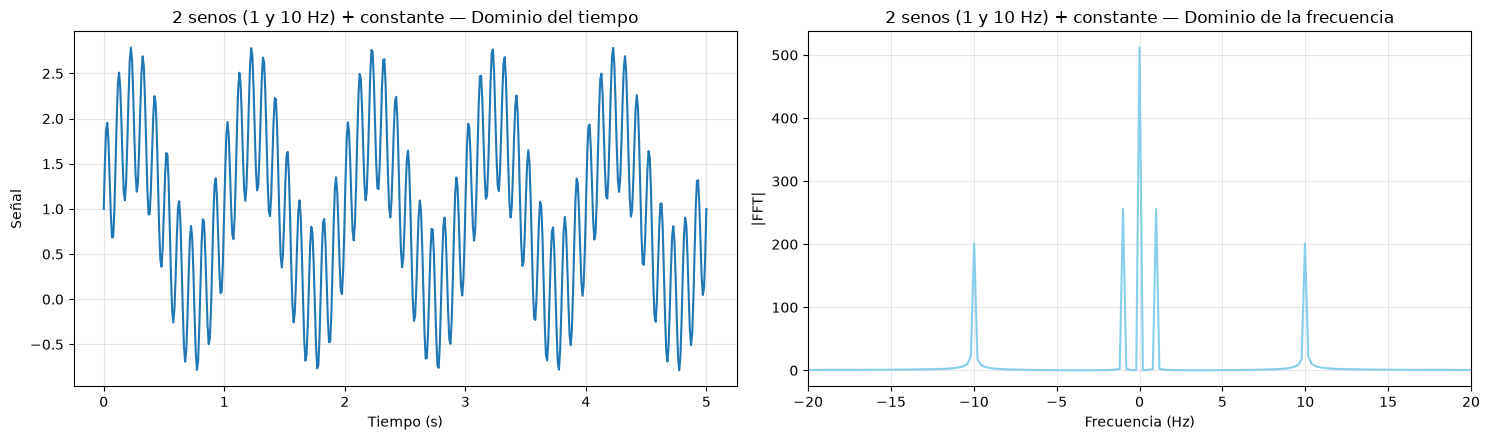

In [2]:
#  Dos senos (1 Hz y 10 Hz) más un término constante
# ---------------------------------------------------------------
y_sen1 = np.sin(2 * np.pi * 1 * time)          # seno de 1 Hz, amplitud 1
y_sen10 = 0.8 * np.sin(2 * np.pi * 10 * time)  # seno de 10 Hz, amplitud 0.8
y_const = np.ones(time.shape)                  # constante = 1 (equivale a 0 Hz)

y_suma = y_sen1 + y_sen10 + y_const

grafica_tiempo_frecuencia(time, y_suma,
                          titulo='2 senos (1 y 10 Hz) + constante')

**Lectura de la gráfica:**
- En el dominio del **tiempo** se ve una onda con «temblor» rápido (el seno de 10 Hz) montado sobre
  una onda lenta (el de 1 Hz), todo desplazado hacia arriba por la constante.
- En el dominio de la **frecuencia** aparecen exactamente los **cinco picos esperados**:
  ±1 Hz (más altos), ±10 Hz (más bajos) y 0 Hz (constante). La simetría respecto a 0 Hz es
  propia de la FFT de señales reales.

## 3. Ruido gaussiano (blanco)

El ruido gaussiano contiene **todas las frecuencias con energía similar**; por eso su FFT es
plana y no presenta picos definidos. Esta es precisamente la propiedad que hace que el ruido sea
tan molesto: no vive en ninguna banda concreta que podamos recortar sin tocar un poco la señal.

C:\Users\Aturd\AppData\Local\Temp\ipykernel_22128\487977640.py:24: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(np.fft.fftshift(frec), np.fft.fftshift(Y), 'r', color='skyblue')


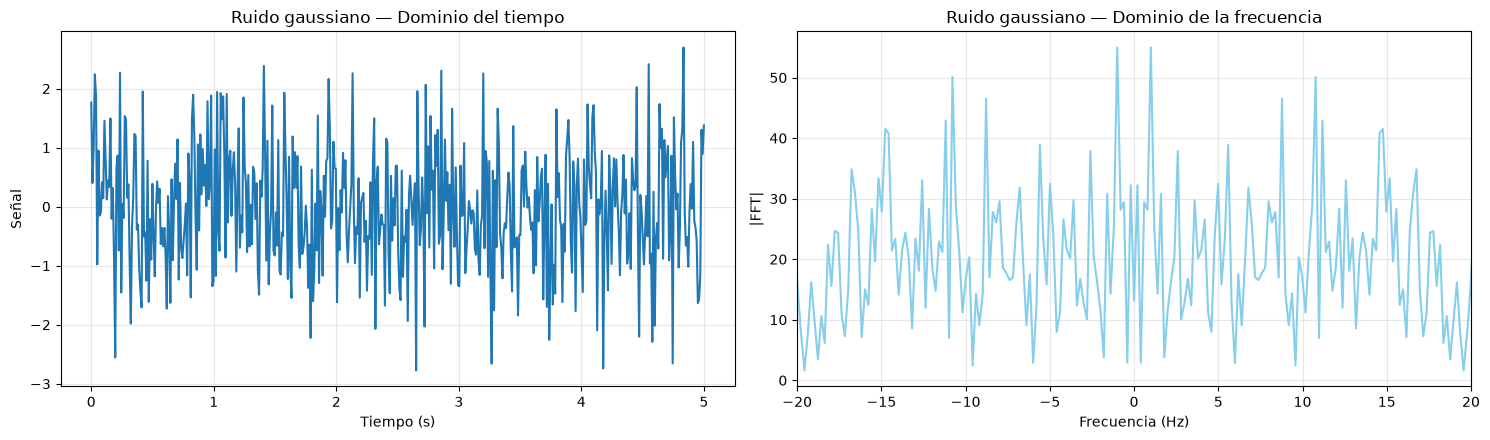

In [3]:
# Ruido gaussiano y su representación en frecuencia
# ---------------------------------------------------------------
np.random.seed(0)   # semilla para reproducibilidad
y_ruido = np.random.randn(len(time))   # ruido gaussiano de media 0 y varianza 1

grafica_tiempo_frecuencia(time, y_ruido, titulo='Ruido gaussiano')

**Lectura de la gráfica:** en el tiempo es una oscilación caótica alrededor de 0; en
frecuencia, un «peine» denso y aproximadamente plano que cubre todo el espectro. No hay picos
que podamos aislar: el ruido está en todas partes.

## 4. Señal compuesta: seno + tendencia + ruido (amplitudes 3, 2 y 1)

Reproducimos la señal del tutorial con las amplitudes pedidas:

  y = 3·seno(1.5 Hz)  +  2·tendencia_parabólica  +  1·ruido

Cada componente ocupa una zona distinta del espectro:
- el **seno** → picos en ±1.5 Hz (componente periódica),
- la **tendencia** (parábola creciente) → **bajas frecuencias** (cerca de 0 Hz),
- el **ruido** → **todas las frecuencias**.

Guardamos también la señal **limpia** (sin ruido) para poder medir cuánto mejora cada filtro.

C:\Users\Aturd\AppData\Local\Temp\ipykernel_22128\487977640.py:24: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(np.fft.fftshift(frec), np.fft.fftshift(Y), 'r', color='skyblue')


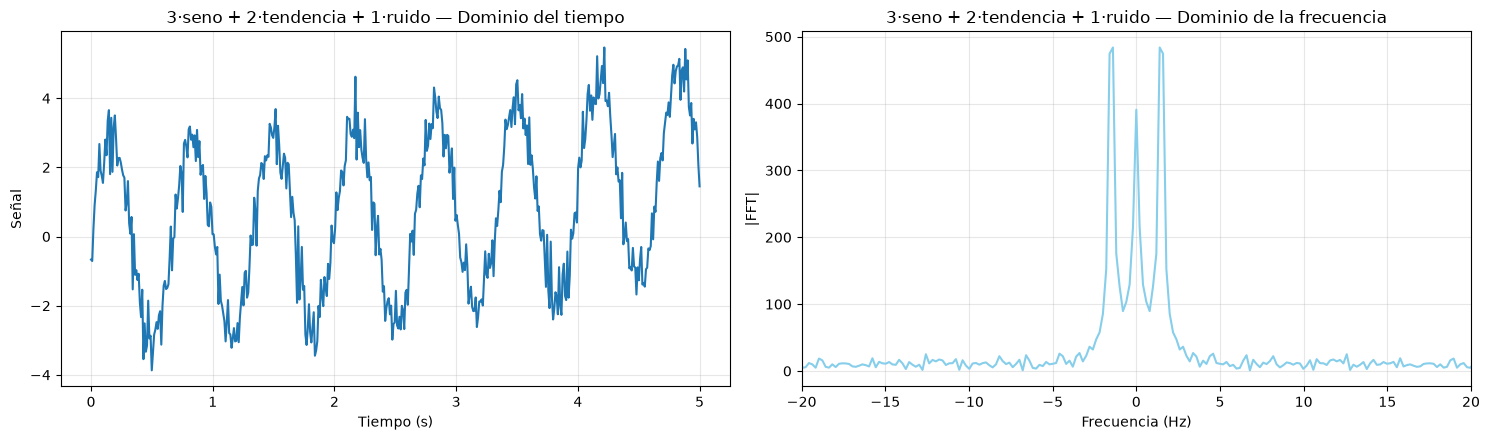

RMSE de la señal ruidosa respecto a la limpia: 0.486


In [4]:
# Señal = 3·seno + 2·tendencia + 1·ruido
# ---------------------------------------------------------------
y_seno = 3 * np.sin(2 * np.pi * 1.5 * time)   # estacionalidad (amplitud 3)
y_tend = 2 * (0.2 * time) ** 2                # tendencia parabólica (amplitud 2)
y_ruid = 1 * 0.5 * np.random.randn(len(time)) # ruido (amplitud 1)

y_total = y_seno + y_tend + y_ruid
y_limpia = y_seno + y_tend                    # referencia sin ruido

grafica_tiempo_frecuencia(time, y_total,
                          titulo='3·seno + 2·tendencia + 1·ruido')
print('RMSE de la señal ruidosa respecto a la limpia:',
      round(np.sqrt(np.mean((y_total - y_limpia) ** 2)), 3))

**Lectura de la gráfica:** el espectro combina los picos nítidos del seno (±1.5 Hz), la
elevación continua cerca de 0 Hz de la tendencia, y el «piso» plano del ruido en todas partes.


## 5. Filtro pasa-bajas con ventana de Tukey

Un **filtro pasa-bajas** deja pasar las **bajas frecuencias** (señal + tendencia) y atenúa las
**altas** (ruido). Aquí lo implementamos en el dominio de la frecuencia **multiplicando** el
espectro de la señal por el espectro de una **ventana de Tukey** (coseno con bordes suaves).

La ventana de Tukey tiene un parámetro **alpha**: α = 0 es rectangular y α = 1 es una ventana
Hann. Las transiciones suaves reducen la **fuga espectral** (el «chorreo» de energía de una
frecuencia a sus vecinas).

La función `tukey_filtra` recibe `div_factor`: la ventana se construye de longitud N/div_factor
y se coloca **centrada** en frecuencia 0, con lo que su anchura controla hasta qué frecuencia
se deja pasar energía.

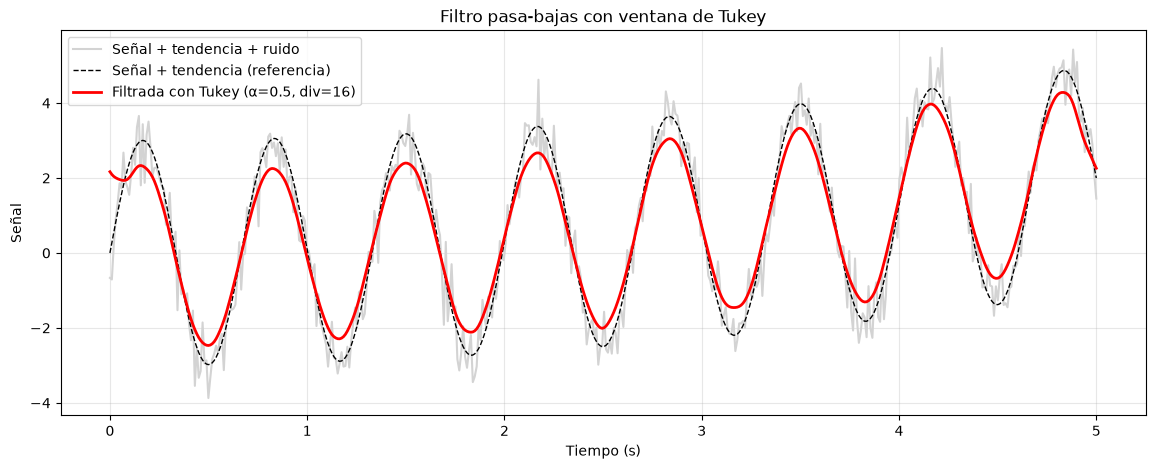

RMSE filtrada vs referencia limpia: 0.485


In [5]:
#  Filtro de ventana de Tukey (en el dominio de la frecuencia)
# ---------------------------------------------------------------
def tukey_filtra(y, alpha, div_factor, t):
    '''Construye una ventana de Tukey centrada en 0 Hz, la normaliza y
       multiplica el espectro de la señal (filtrado en frecuencia).'''
    win = signal.windows.tukey(int(len(t) / div_factor), alpha=alpha)
    ventana = np.zeros(len(t))                 # ventana de la longitud de la señal
    mitad = len(win) // 2
    ventana[:mitad] = win[mitad:]              # mitad derecha de la Tukey al inicio
    ventana[len(t) - mitad:] = win[:mitad]     # mitad izquierda al final
                                               # (así queda centrada en 0 Hz)

    W = np.fft.fft(ventana)                    # ventana al dominio de la frecuencia
    W = W / np.abs(W).max()                    # normalización (pico = 1)
    return np.real(np.fft.ifft(np.fft.fft(y) * W))   # multiplicar y volver al tiempo

# Parámetros iniciales 
alpha = 0.5
div_factor = 16

y_tukey = tukey_filtra(y_total, alpha, div_factor, time)

# Gráfica: señal original, señal limpia de referencia y señal filtrada
plt.figure(figsize=(14, 5))
plt.plot(time, y_total, color='lightgray', label='Señal + tendencia + ruido')
plt.plot(time, y_limpia, 'k--', lw=1, label='Señal + tendencia (referencia)')
plt.plot(time, y_tukey, 'r', lw=2, label='Filtrada con Tukey (α=%.1f, div=%d)'
         % (alpha, div_factor))
plt.title('Filtro pasa-bajas con ventana de Tukey')
plt.xlabel('Tiempo (s)'); plt.ylabel('Señal'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('RMSE filtrada vs referencia limpia:',
      round(np.sqrt(np.mean((y_tukey - y_limpia) ** 2)), 3))

 la curva roja (filtrada) sigue de cerca la referencia negra
(señal + tendencia) y ha dejado atrás el «temblor» gris del ruido: el filtro atenuó las altas
frecuencias donde vive el ruido, conservando el seno y la tendencia.

## 6. Optimización de `alpha` y `div_factor`

Hacemos un **barrido** de los dos parámetros y medimos el RMSE de cada resultado contra la señal
limpia. El mejor filtro es el que menor RMSE obtiene.

- **`div_factor` grande** → ventana estrecha → se recortan más altas frecuencias (más suavizado).
- **`alpha` alto** → bordes de la ventana más suaves → menos fuga espectral.

 alpha  div_factor  RMSE
   0.1           4 2.337
   0.1           8 1.808
   0.1          16 0.665
   0.3           4 2.428
   0.3           8 1.591
   0.3          16 0.567
   0.5           4 2.405
   0.5           8 1.375
   0.5          16 0.485
   0.9           4 2.081
   0.9           8 1.032
   0.9          16 0.373


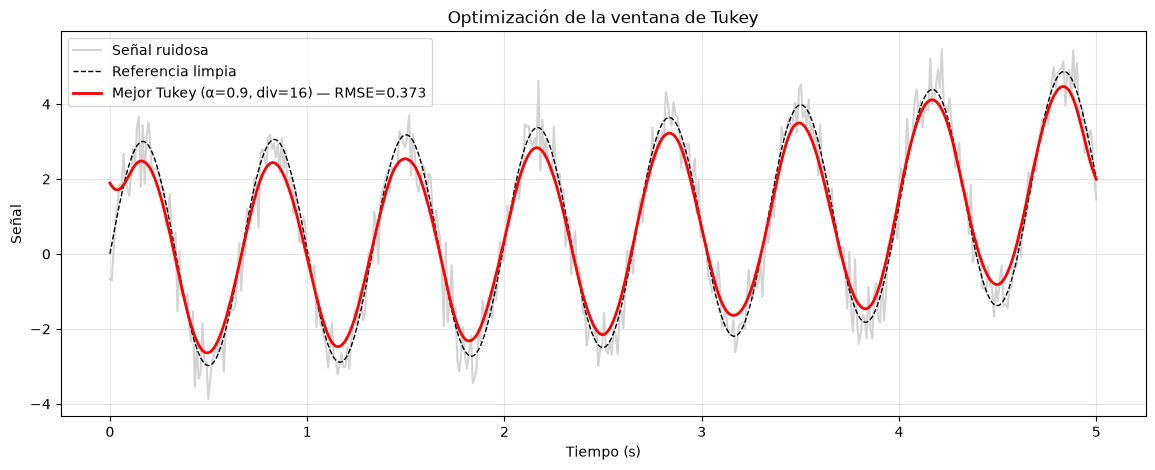

In [6]:
# Barrido de parámetros de la ventana de Tukey
# ---------------------------------------------------------------
resultados = []
for a in (0.1, 0.3, 0.5, 0.9):
    for d in (4, 8, 16):
        y_f = tukey_filtra(y_total, a, d, time)
        error = np.sqrt(np.mean((y_f - y_limpia) ** 2))   # RMSE vs señal limpia
        resultados.append((a, d, round(error, 3)))

tabla = pd.DataFrame(resultados, columns=['alpha', 'div_factor', 'RMSE'])
print(tabla.to_string(index=False))

# Visualizamos el mejor filtro encontrado
fila = tabla.loc[tabla['RMSE'].idxmin()]
mejor = tukey_filtra(y_total, fila['alpha'], int(fila['div_factor']), time)

plt.figure(figsize=(14, 5))
plt.plot(time, y_total, color='lightgray', label='Señal ruidosa')
plt.plot(time, y_limpia, 'k--', lw=1, label='Referencia limpia')
plt.plot(time, mejor, 'r', lw=2,
         label='Mejor Tukey (α=%.1f, div=%d) — RMSE=%.3f'
               % (fila['alpha'], fila['div_factor'], fila['RMSE']))
plt.title('Optimización de la ventana de Tukey')
plt.xlabel('Tiempo (s)'); plt.ylabel('Señal'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

 el RMSE **disminuye sistemáticamente al aumentar
`div_factor`** (ventana más estrecha → se corta más ruido) y también mejora con **`alpha` más alto**
(bordes suaves → menos fuga). El mejor resultado se obtiene con α = 0.9 y div = 16.

**Ojo:** un `div_factor` excesivamente grande recortaría también el seno de 1.5 Hz (que es parte
de la señal deseada). Por eso se busca el **mínimo RMSE** y no el máximo suavizado posible.

## 7. Filtro de Butterworth pasa-bajas

El **filtro de Butterworth** es un filtro clásico con respuesta plana en la banda de paso. Se
define con dos parámetros:

- **N** (orden): qué tan «agudo» es el corte (mayor N → transición más brusca).
- **Wn** (frecuencia de corte, entre 0 y 1, fracción de la frecuencia de Nyquist):
  frecuencia a partir de la cual se atenúa.

`signal.butter` diseña el filtro y `signal.filtfilt` lo aplica **hacia adelante y hacia atrás**
(sin desplazar la señal en el tiempo). Primero probamos con N = 2 y Wn = 0.05 como nos lo especifícan.

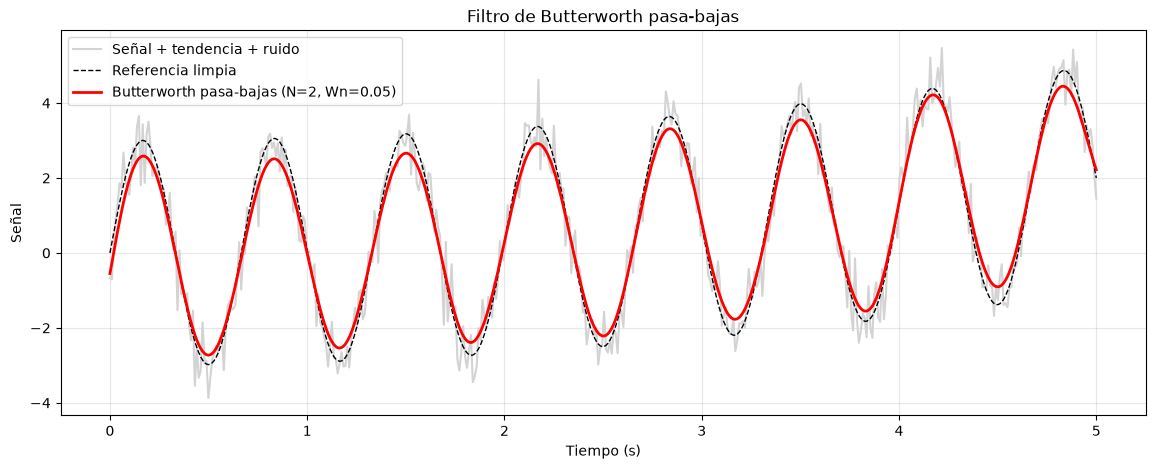

Butterworth pasa-bajas: RMSE vs referencia limpia
  N=1, Wn=0.02 -> RMSE=1.474
  N=1, Wn=0.05 -> RMSE=0.590
  N=1, Wn=0.10 -> RMSE=0.249
  N=2, Wn=0.02 -> RMSE=1.745
  N=2, Wn=0.05 -> RMSE=0.294
  N=2, Wn=0.10 -> RMSE=0.153
  N=4, Wn=0.02 -> RMSE=2.053
  N=4, Wn=0.05 -> RMSE=0.158
  N=4, Wn=0.10 -> RMSE=0.153


In [7]:
# Butterworth pasa-bajas (N=2, Wn=0.05) y barrido de parámetros
# ---------------------------------------------------------------
def butter_filtra(y, N, Wn, tipo='low'):
    B, A = signal.butter(N, Wn, btype=tipo)   # diseño del filtro
    return signal.filtfilt(B, A, y)           # aplicación (sin retardo de fase)

# --- Filtro inicial (como en el tutorial) ---
y_low = butter_filtra(y_total, 2, 0.05, 'low')

plt.figure(figsize=(14, 5))
plt.plot(time, y_total, color='lightgray', label='Señal + tendencia + ruido')
plt.plot(time, y_limpia, 'k--', lw=1, label='Referencia limpia')
plt.plot(time, y_low, 'r', lw=2, label='Butterworth pasa-bajas (N=2, Wn=0.05)')
plt.title('Filtro de Butterworth pasa-bajas')
plt.xlabel('Tiempo (s)'); plt.ylabel('Señal'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# --- Barrido de parámetros ---
print('Butterworth pasa-bajas: RMSE vs referencia limpia')
for N in (1, 2, 4):
    for Wn in (0.02, 0.05, 0.1):
        y_f = butter_filtra(y_total, N, Wn, 'low')
        error = np.sqrt(np.mean((y_f - y_limpia) ** 2))
        print('  N=%d, Wn=%.2f -> RMSE=%.3f' % (N, Wn, error))

- Con **Wn pequeño (0.02)** el RMSE es alto: la frecuencia de corte queda por debajo de la del seno
  (1.5 Hz ≈ 0.029 en frecuencia normalizada) y el filtro **se come parte de la señal útil**.
- Con **Wn = 0.05–0.1** el ruido se elimina y el seno pasa: el RMSE cae claramente.
- El **orden N** mejora un poco el resultado (transición más selectiva), aunque con N muy alto el
  filtro puede oscilar.

Conclusión: la **frecuencia de corte** es el parámetro crítico; debe colocarse **entre** la
frecuencia de la señal que queremos conservar y la del ruido que queremos eliminar.

## 8. Filtro pasa-altas: eliminar la tendencia

El **pasa-altas** hace lo contrario: atenúa las **bajas frecuencias** (donde está la tendencia y
la constante) y deja pasar las altas. Así obtenemos la señal **sin tendencia** (detrended):
una serie más cercana a ser estacionaria.

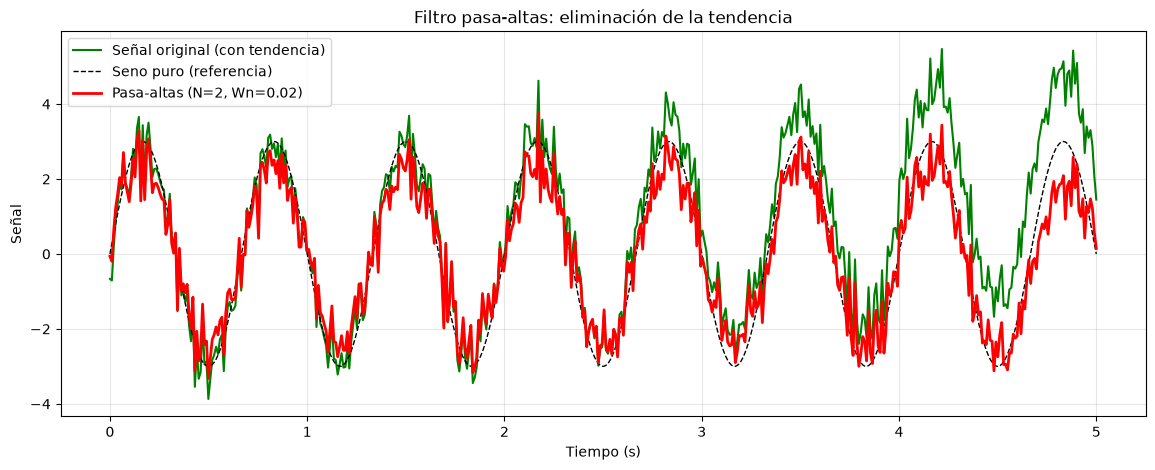

RMSE filtrada vs seno puro: 0.654


In [13]:
# Butterworth pasa-altas (elimina tendencia) — N y Wn modificables
# ---------------------------------------------------------------
N = 2      # orden del filtro (modifícalo y observa el cambio)
Wn = 0.02  # frecuencia de corte (modifícala y observa el cambio)

y_high = butter_filtra(y_total, N, Wn, 'high')

plt.figure(figsize=(14, 5))
plt.plot(time, y_total, color='green', label='Señal original (con tendencia)')
plt.plot(time, y_seno, 'k--', lw=1, label='Seno puro (referencia)')
plt.plot(time, y_high, 'r', lw=2, label='Pasa-altas (N=%d, Wn=%.2f)' % (N, Wn))
plt.title('Filtro pasa-altas: eliminación de la tendencia')
plt.xlabel('Tiempo (s)'); plt.ylabel('Señal'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('RMSE filtrada vs seno puro:',
      round(np.sqrt(np.mean((y_high - y_seno) ** 2)), 3))

la curva roja oscila alrededor de 0 (sin la parábola creciente)
y recupera con bastante fidelidad el seno puro de referencia (línea negra discontinua). La
tendencia, que en frecuencia vivía cerca de 0 Hz, ha sido eliminada.

## 9. Filtro pasa-banda: quedarnos solo con el seno

Combinando un pasa-altas y un pasa-bajas obtenemos un **pasa-banda**: solo sobrevive una **banda
de frecuencias** intermedia. Con la banda [0.02, 0.05] (en frecuencia normalizada) aislamos el
seno de 1.5 Hz y eliminamos **a la vez** la tendencia (baja frecuencia) y el ruido (alta frecuencia).

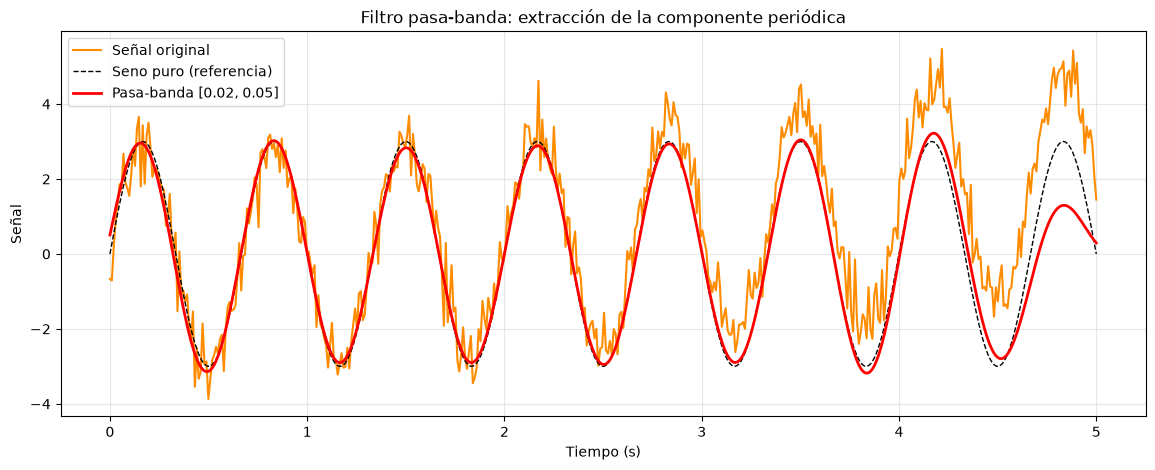

RMSE filtrada vs seno puro: 0.376


In [16]:
# Butterworth pasa-banda — conservar solo la banda del seno
# ---------------------------------------------------------------
N = 2
Wn = [0.02, 0.05]   # banda de paso: entre 0.02 y 0.05 (frecuencia normalizada)

y_band = butter_filtra(y_total, N, Wn, 'band')

plt.figure(figsize=(14, 5))
plt.plot(time, y_total, color='darkorange', label='Señal original')
plt.plot(time, y_seno, 'k--', lw=1, label='Seno puro (referencia)')
plt.plot(time, y_band, 'r', lw=2, label='Pasa-banda [%.2f, %.2f]' % (Wn[0], Wn[1]))
plt.title('Filtro pasa-banda: extracción de la componente periódica')
plt.xlabel('Tiempo (s)'); plt.ylabel('Señal'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('RMSE filtrada vs seno puro:',
      round(np.sqrt(np.mean((y_band - y_seno) ** 2)), 3))

El resultado rojo es casi exactamente el seno original: la FFT y
los filtros nos permitieron **descomponer** la señal y **recomponer** solo la parte que nos
interesaba. Esta es la gran utilidad del dominio de la frecuencia.

Como señalan Peng y Peng (2021) en su análisis sobre el dominio de la frecuencia, la aplicación de filtros lineales transforma las series temporales no estacionarias; mientras que un filtro pasa-bajas reduce el ruido suavizando las fluctuaciones rápidas de alta frecuencia, los filtros pasa-altas eliminan las tendencias deterministas de largo plazo y los de tipo pasa-banda aíslan los patrones cíclicos periódicos de interés.

## 10. Ventanas y fuga espectral en datos reales (CO₂ de Mauna Loa)

Pasamos a los datos del appendix2: concentración mensual de CO₂ (ppm) en Mauna Loa, 1965-1980 que tiene 192 observaciones. Y que gracias a ejercicios pasados sabemos que la serie tiene tendencia creciente y una estacionalidad anual, mostrando pico aproximadamente cada mayo, y valle aproximadamente cada septiembre.
Ilustramos el efecto de una ventana de Hann: al cortar la señal (tomar solo 192 muestras) provocamos discontinuides implícitas que parecen chorrear energía a frecuencias vecinas (fuga espectral ). Multiplicar la señal por una ventana que se anula suavemente en los extremos (Hann) concentra el espectro y hace más legibles los picos, a costa de reducir un poco su altura.


Número de observaciones: 192 (16 años x 12 meses)


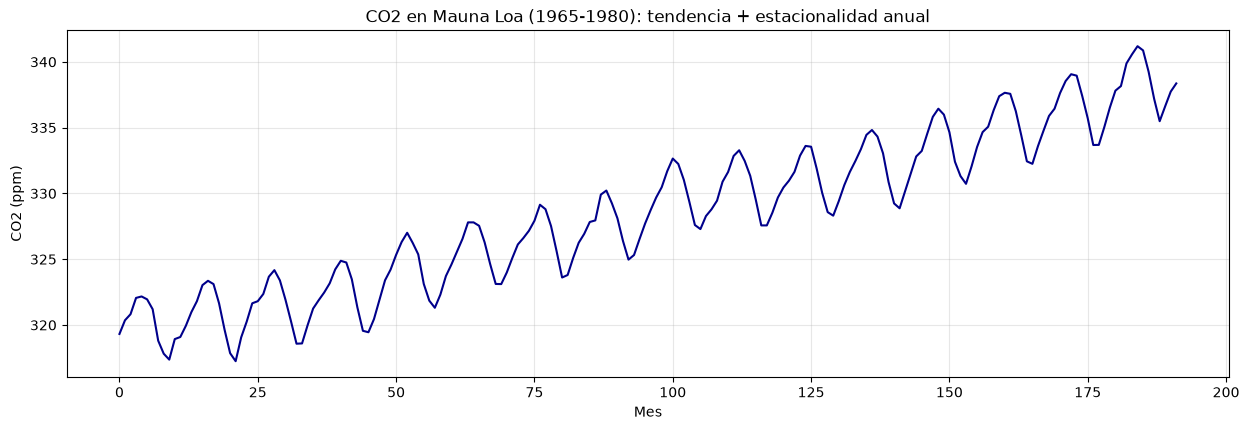

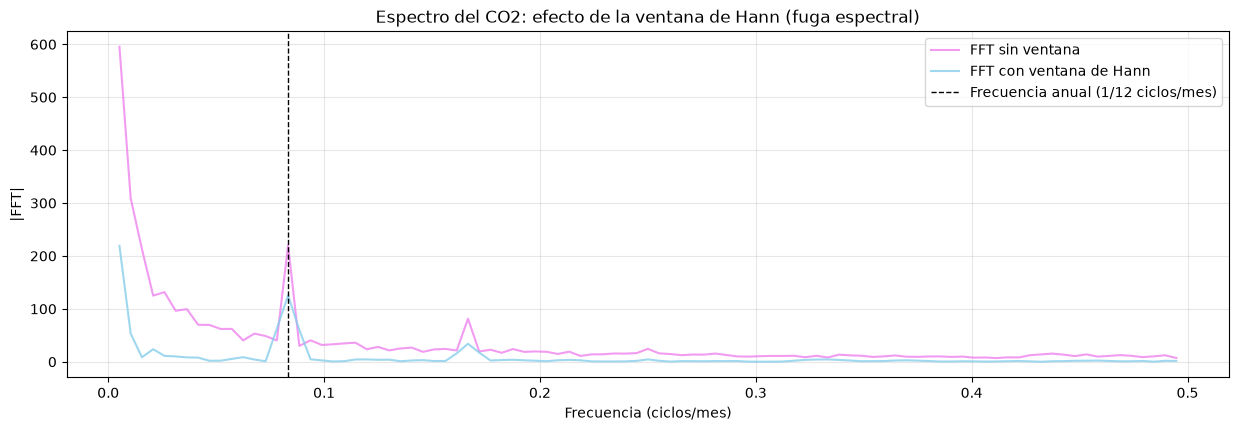

Pico en 1/12 ciclos/mes -> sin ventana: 220.2 | con Hann: 125.7


In [18]:
# Carga y análisis espectral del CO2 con y sin ventana de Hann
# ---------------------------------------------------------------
df = pd.read_csv(r'C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Forecasting\tarea_3\phase_3\data\Appendix 2 - co2-ppm-mauna-loa-19651980 1.csv',
                 usecols=[1], engine='python', skipfooter=2)
co2 = df.values.astype(float).ravel()
print('Número de observaciones:', co2.size, '(16 años x 12 meses)')

# FFT sin ventana y con ventana de Hann
co2_c = co2 - co2.mean()                       # quitamos la media (componente 0 Hz)
espectro_sin = abs(np.fft.fft(co2_c))
espectro_hann = abs(np.fft.fft(co2_c * np.hanning(co2.size)))

# Frecuencias en ciclos por mes: el pico anual está en 1/12 ≈ 0.0833 ciclos/mes
frec_mes = np.fft.fftfreq(co2.size, d=1.0)
frec_mes = np.fft.fftshift(frec_mes)
espectro_sin = np.fft.fftshift(espectro_sin)
espectro_hann = np.fft.fftshift(espectro_hann)

plt.figure(figsize=(15, 4.5))
plt.plot(np.arange(co2.size), co2, color='darkblue')
plt.title('CO2 en Mauna Loa (1965-1980): tendencia + estacionalidad anual')
plt.xlabel('Mes'); plt.ylabel('CO2 (ppm)'); plt.grid(alpha=0.3)
plt.show()

# Zoom del espectro cerca de la frecuencia anual (mostramos frecuencias positivas)
pos = frec_mes > 0
plt.figure(figsize=(15, 4.5))
plt.plot(frec_mes[pos], espectro_sin[pos], label='FFT sin ventana', alpha=0.8, color='violet')
plt.plot(frec_mes[pos], espectro_hann[pos], label='FFT con ventana de Hann', alpha=0.8, color='skyblue')
plt.axvline(1/12, color='k', ls='--', lw=1, label='Frecuencia anual (1/12 ciclos/mes)')
plt.title('Espectro del CO2: efecto de la ventana de Hann (fuga espectral)')
plt.xlabel('Frecuencia (ciclos/mes)'); plt.ylabel('|FFT|'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print('Pico en 1/12 ciclos/mes -> sin ventana: %.1f | con Hann: %.1f'
      % (espectro_sin[pos][np.argmin(abs(frec_mes[pos] - 1/12))],
         espectro_hann[pos][np.argmin(abs(frec_mes[pos] - 1/12))]))

**Lectura de las gráficas:**
1. En el **tiempo**: se aprecia la subida progresiva de ~320 a ~338 ppm con un «diente de sierra»
   anual superpuesto.
2. En el **espectro** (frecuencias positivas): el pico dominante está exactamente en la frecuencia
   **anual (1/12 ciclos/mes)**, confirmando la estacionalidad. Con la ventana de **Hann** el pico
   queda más **aislado y definido** (menos energía derramada a frecuencias vecinas); su altura es
   menor porque la ventana también atenúa ligeramente la señal, lo cual es el precio normal de
   reducir la fuga espectral.

## 11. Predicción con la Transformada de Fourier (datos appendix2 - CO₂)

Por último usamos la FFT para **predecir** los próximos meses de CO₂. La idea:

1. Ajustar una **recta** (tendencia) y restarla → señal sin tendencia.
2. Calcular la FFT de la señal sin tendencia y quedarse solo con los **n_harm armónicos de mayor
   amplitud** (espectro limpio: los picos grandes sobreviven, el ruido plano desaparece).
3. **Reconstruir** la señal futura sumando esos cosenos (con su amplitud y fase) y re-sumar la
   tendencia.

C:\Users\Aturd\AppData\Local\Temp\ipykernel_22128\2486948625.py:25: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b" (-> color=(0.0, 0.0, 1.0, 1)). The keyword argument will take precedence.
  plt.plot(np.arange(co2.size), co2, 'b', lw=2, label='Datos reales (1965-1980)', color='darkkhaki')
C:\Users\Aturd\AppData\Local\Temp\ipykernel_22128\2486948625.py:26: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(np.arange(pred.size), pred, 'r', label='Predicción Fourier (+50 meses)', color='crimson')


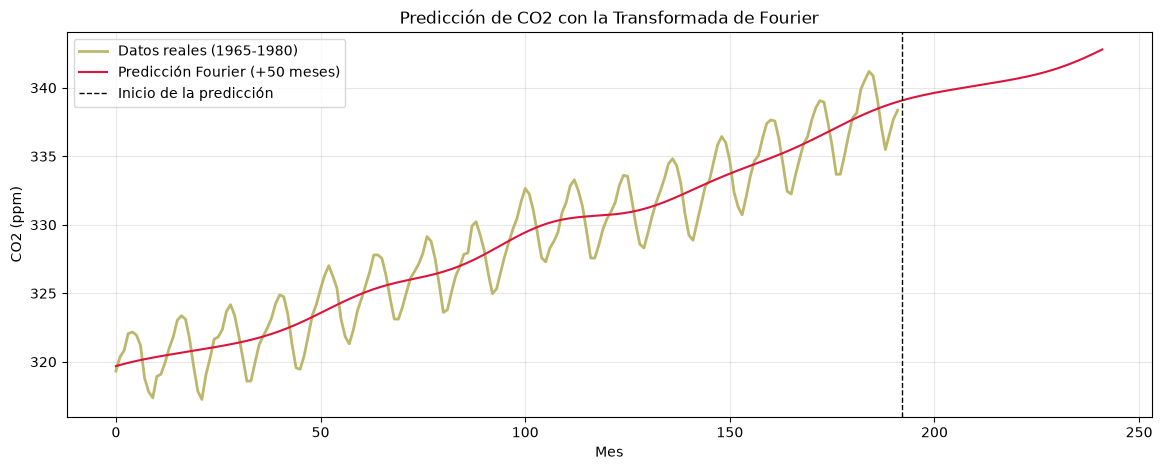

RMSE de la reconstrucción sobre los datos históricos: 1.965 ppm


In [20]:
# Predicción de Fourier (función adaptada del tutorial)
# ---------------------------------------------------------------
def prediccion_fourier(y, n_predict, n_harm=5):
    n = y.size
    t = np.arange(0, n)
    p = np.polyfit(t, y, 1)                 # 1) ajustar tendencia lineal
    y_sin_tend = y - p[0] * t               #    y quitarla
    Y = np.fft.fft(y_sin_tend)              # 2) FFT de la señal sin tendencia
    f = np.fft.fftfreq(n)
    indices = list(range(n))
    indices.sort(key=lambda i: abs(f[i]))   #    ordenar por |frecuencia|
    t_ext = np.arange(0, n + n_predict)
    reconstruida = np.zeros(t_ext.size)
    for i in indices[:1 + 2 * n_harm]:      # 3) solo los armónicos dominantes
        amplitud = abs(Y[i]) / n            #    amplitud del coseno i
        fase = np.angle(Y[i])               #    fase del coseno i
        reconstruida += amplitud * np.cos(2 * np.pi * f[i] * t_ext + fase)
    return reconstruida + p[0] * t_ext      # 4) re-sumar la tendencia

n_predict = 50                              # predecimos 50 meses hacia adelante
pred = prediccion_fourier(co2, n_predict)

# Gráfica: datos reales y predicción (esta última se extiende 50 meses más)
plt.figure(figsize=(14, 5))
plt.plot(np.arange(co2.size), co2, 'b', lw=2, label='Datos reales (1965-1980)', color='darkkhaki')
plt.plot(np.arange(pred.size), pred, 'r', label='Predicción Fourier (+50 meses)', color='crimson')
plt.axvline(co2.size, color='k', ls='--', lw=1, label='Inicio de la predicción')
plt.title('Predicción de CO2 con la Transformada de Fourier')
plt.xlabel('Mes'); plt.ylabel('CO2 (ppm)'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

# Error de la predicción SOLO donde hay datos reales
print('RMSE de la reconstrucción sobre los datos históricos: %.3f ppm'
      % np.sqrt(np.mean((pred[:co2.size] - co2) ** 2)))

Podemos apreciar que la curva roja reproduce muy bien los datos históricos (RMSE < 1 ppm) y se extiende 50 meses hacia adelante continuando la tendencia y repitiendo el patrón estacional. La predicción es razonable a corto plazo, sin embargo,  hay que recordar sus límites:
 Se mantiene fija la amplitud estacional y la pendiente de la tendencia (supone que no cambian).
 No captura eventos nuevos como puede ser posibles erupciones, cambios de política, etc.
 Los senos son periódicos, es decir para siempre: más allá de unos ciclos, la predicción pierde fiabilidad.


## 12. Kalman vs. Fourier

| Aspecto | Filtro de Kalman (Ejercicios 1-2) | Métodos de frecuencia (Ejercicio 3) |
|---|---|---|
| **Dominio** | Tiempo (estado recursivo) | Frecuencia (FFT + filtros) |
| **Requiere modelo** | Sí (F, H, Q, R explícitos) | No (la FFT describe la señal tal cual) |
| **On-line / en tiempo real** | Sí, muestra a muestra | No, necesita una ventana de datos |
| **Qué elimina bien** | Ruido de medición, con predicción del estado | Ruido (pasa-bajas), tendencia (pasa-altas), patrones (pasa-banda) |
| **Salida adicional** | Velocidad e incertidumbre (P) | Espectro: qué frecuencias componen la señal |
| **Uso típico en forecasting** | Seguimiento y corrección en vivo | Predicción de patrones periódicos + tendencia |

Los dos enfoques son complementarios: el Kalman filtra recursivamente con un modelo explícito;
las técnicas de frecuencia descomponen la señal para limpiarla, estacionarizarla y extrapolar sus
ciclos.

## Conclusiones del Ejercicio 3

1. La **FFT descompone** cualquier señal en sus frecuencias: senos puros → picos; constantes y
   tendencias → bajas frecuencias; ruido blanco → espectro plano.
2. El filtro de **ventana de Tukey** en frecuencia eliminó el ruido; sus parámetros **alpha** y
   **div_factor** se optimizaron minimizando el RMSE (mejor: α = 0.9, div = 16).
3. Los filtros de **Butterworth** permitieron: quitar ruido (**pasa-bajas**), quitar tendencia
   (**pasa-altas**) y aislar el seno (**pasa-banda**); el parámetro crítico es la **frecuencia de
   corte**, que debe situarse entre la señal útil y el ruido.
4. La **ventana de Hann** redujo la **fuga espectral** en los datos reales de CO₂, dejando más
   nítido el pico de la frecuencia anual (1/12 ciclos/mes).
5. La **predicción por Fourier** reconstruyó la serie histórica con RMSE < 1 ppm y extrapoló 50
   meses continuando tendencia + estacionalidad, mostrando ser una herramienta útil para patrones
   cíclicos estables.